# Medicare Claims Intelligence

**A dbt claims warehouse, an ILI forecast, provider fraud detection, and a high-cost risk model, built on public CMS Medicare claims and CDC surveillance data.**

| | Question | Approach | Result |
|---|---|---|---|
| 1 | Can the claims data be trusted? | dbt + DuckDB warehouse: 4 staging models, 5 marts, 26 data tests | Found 11,253 outpatient claims with no service date |
| 2 | How many ILI visits should we staff for 1-4 weeks out? | Harmonic regression + ARIMA errors, 35-origin rolling backtest | **MASE 0.62** vs 1.06 for seasonal naive |
| 3 | Which providers should program integrity review? | Robust z, MCD Mahalanobis, Isolation Forest, max-rank ensemble; tested on injected billing schemes | **81% precision** at a 2% review capacity (random: 2%) |
| 4 | Who will be in next year's top 5% of cost? | Out-of-time XGBoost vs prior-year cost, SHAP, MLflow | Captures **21.0%** of next year's high-cost members vs 14.4% (**+46%**) |

**Data**

- **CMS 2008-2010 Medicare DE-SynPUF, Sample 1:** synthetic fee-for-service claims (116K beneficiaries, 790K outpatient claims, 66K inpatient claims, 5.5M Part D events) in the same layout as CMS research files. It is synthetic, so findings describe the method, not the Medicare population.
- **CDC ILINet** via the Delphi Epidata API: weekly national influenza-like-illness visits, 2010-2026.

Setup: `pip install -r requirements.txt`, `python scripts/download_data.py`, `dbt build --project-dir dbt --profiles-dir dbt`.

In [1]:
import json, os, warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

ROOT = Path.cwd()
RAW = ROOT / "data" / "raw"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

con = duckdb.connect(str(ROOT / "data" / "warehouse.duckdb"), read_only=True)
con.execute(f"SET file_search_path = '{ROOT}'")   # staging views read data/raw relative to the project root
q = lambda sql: con.sql(sql).df()

---
## 1. Claims warehouse and data quality

`dbt build` turns the raw CSVs into typed, keyed staging views and analysis marts in DuckDB, and runs the data tests. Two modeling decisions matter for every downstream number:

- **Claim key = `(CLM_ID, SEGMENT)`.** Long institutional claims are split into segments, so keying on `CLM_ID` alone fans out joins and double-counts payments. A dbt `unique` test enforces the composite key.
- **Exposure.** Utilization is reported per 1,000 members in force, so changes in membership are not mistaken for changes in health.

```
raw CSVs ─► stg_beneficiary ─┬─► mart_members_in_force ─► mart_daily_claims
            stg_outpatient ──┼─► mart_provider_features
            stg_inpatient  ──┼─► mart_member_year ─► mart_risk_dataset
            stg_rx_events  ──┘
```

In [2]:
# dbt's own test results: the warnings are real findings about the data.
results = json.loads((ROOT / "dbt/target/run_results.json").read_text())["results"]
tests = pd.DataFrame([{"test": r["unique_id"].split(".")[2], "status": r["status"], "failures": r.get("failures")}
                      for r in results if r["unique_id"].startswith("test.")])
print(len(tests), "tests:", tests.status.value_counts().to_dict())
tests[tests.status != "pass"]

26 tests: {'pass': 24, 'warn': 2}


,test,status,failures
2,assert_claims_within_coverage_window,warn,1
3,not_null_stg_outpatient_claims_claim_from_date,warn,11253


**11,253 outpatient claims have no service date**, so a daily rollup would silently drop them, and one test flags claims that start before the 2008 coverage window.

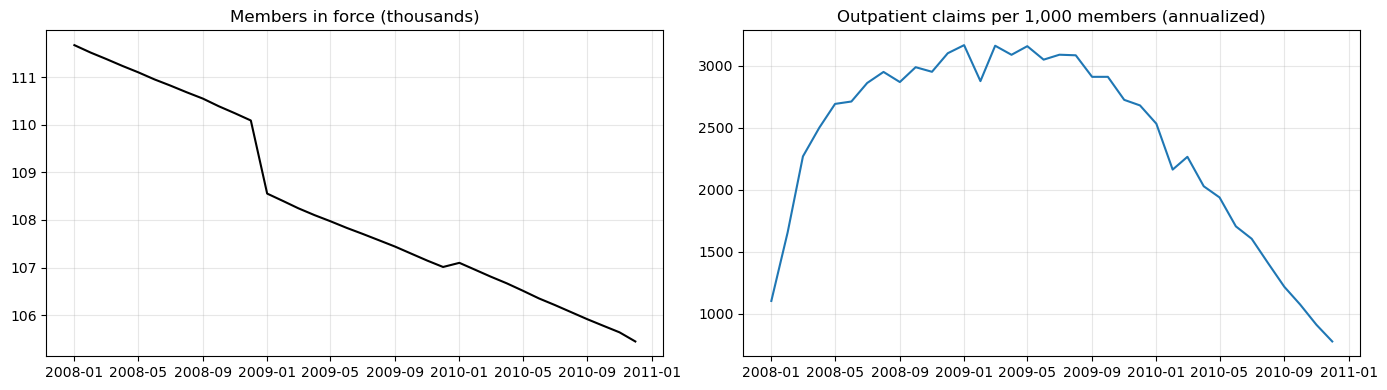

In [3]:
monthly = (q("select * from mart_daily_claims").set_index("claim_date").resample("MS").op_claims.sum().to_frame()
           .join(q("select * from mart_members_in_force").set_index("month_start")))
monthly["op_per_1000"] = 1000 * 12 * monthly.op_claims / monthly.members_in_force   # annualized

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(monthly.members_in_force / 1e3, color="black"); ax[0].set_title("Members in force (thousands)")
ax[1].plot(monthly.op_per_1000); ax[1].set_title("Outpatient claims per 1,000 members (annualized)")
plt.tight_layout(); plt.show()

**The 2010 decline is a data artifact.** Membership falls about 5% over three years, but outpatient claims per 1,000 fall about 70% during 2010. The file is a closed 2008 cohort whose claims were synthesized from donor beneficiaries, so the edges of the window are not representative. That is why the forecast in Section 2 uses a different series, and why the risk label in Section 4 is relative (top 5% within each year).

---
## 2. Forecasting outpatient ILI with a rolling-origin backtest

**Problem.** A care-navigation or urgent-care operator staffs to expected respiratory visits. We forecast national **%ILI** (ILI visits / all visits, which removes the growth in reporting providers) 1-4 weeks ahead with 80% prediction intervals.

**Models** (fit on log %ILI, because flu seasons are multiplicative):

- **Harmonic regression with ARIMA errors:** $\log y_t = \beta_0 + \sum_{k=1}^{4}\big[a_k \sin(2\pi k t/52.18) + b_k \cos(2\pi k t/52.18)\big] + \eta_t$, with $\eta_t \sim \text{ARMA}(2,1)$. Fourier terms carry the annual cycle.
- **Seasonal naive:** $\hat y_{t+h} = y_{t+h-52}$, the benchmark the model must beat.

**Evaluation.** Expanding-window origins every 4 weeks from Oct 2023 to Jun 2026. Each forecast uses only data available at its origin. The metric is MASE: mean absolute error divided by the in-sample error of the seasonal naive forecast, so values below 1 beat "same week last year".

2010-01-03 to 2026-10-11 | 876 weeks


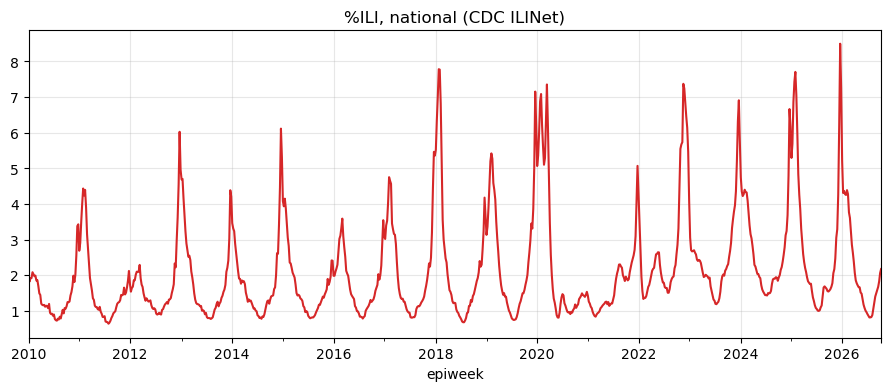

In [4]:
# CDC ILINet (national, weekly). Epiweeks start on Sunday; week 1 is the week containing Jan 4.
def epiweek_to_date(ew):
    year, week = divmod(int(ew), 100)
    jan4 = pd.Timestamp(year=year, month=1, day=4)
    return jan4 - pd.Timedelta(days=(jan4.dayofweek + 1) % 7) + pd.Timedelta(weeks=week - 1)

ili = pd.DataFrame(json.loads((RAW / "ilinet_national.json").read_text())["epidata"])
ili.index = ili.epiweek.map(epiweek_to_date)
y = ili["ili"].sort_index().asfreq("W-SUN").interpolate()        # % of visits that are ILI
print(y.index.min().date(), "to", y.index.max().date(), "|", len(y), "weeks")
y.plot(color="tab:red", title="%ILI, national (CDC ILINet)"); plt.show()

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)

H, ALPHA, M = 4, 0.20, 52       # horizon (weeks), 80% intervals, season length
Z = 1.2816                      # z_{0.9}

def fourier(t, K=4, period=365.25 / 7):
    return np.column_stack([f(2 * np.pi * k * t / period) for k in range(1, K + 1) for f in (np.sin, np.cos)])

def fc_seasonal_naive(train, h):
    sd = (np.log(train) - np.log(train).shift(M)).std()     # spread of same-week-last-year errors
    mean = np.log(train.iloc[-M:-M + h].values)
    return np.exp(mean), np.exp(mean - Z * sd), np.exp(mean + Z * sd)

def fc_harmonic_arima(train, h):
    t = np.arange(len(train) + h)
    model = SARIMAX(np.log(train.values), exog=fourier(t[:-h]), order=(2, 0, 1), trend="c").fit(disp=False)
    pred = model.get_forecast(h, exog=fourier(t[-h:]))
    lo, hi = pred.conf_int(alpha=ALPHA).T
    return np.exp(pred.predicted_mean), np.exp(lo), np.exp(hi)

MODELS = {"seasonal_naive": fc_seasonal_naive, "harmonic_arima": fc_harmonic_arima}

In [6]:
rows = []
for origin in y["2023-10-01":"2026-06-01"].index[::4]:
    train, actual = y[:origin], y[origin:].iloc[1:H + 1]
    if len(actual) < H:
        continue
    scale = np.mean(np.abs(train.values[M:] - train.values[:-M]))     # MASE denominator
    for name, fn in MODELS.items():
        mean, lo, hi = fn(train, H)
        rows += [dict(origin=origin, model=name, h=h + 1, err=abs(actual.iloc[h] - mean[h]), scale=scale,
                      covered=lo[h] <= actual.iloc[h] <= hi[h]) for h in range(H)]
bt = pd.DataFrame(rows)
print(bt.origin.nunique(), "origins x", bt.model.nunique(), "models x", H, "horizons =", len(bt), "forecasts")

summary = bt.groupby("model").apply(lambda g: pd.Series({"MASE": g.err.mean() / g.scale.mean(),
                                                         "coverage_80": g.covered.mean()}))
display(summary.round(3))
bt.pivot_table(index="model", columns="h", values="err").round(3).add_prefix("MAE h=")

35 origins x 2 models x 4 horizons = 280 forecasts


,MASE,coverage_80
model,,
harmonic_arima,0.619,0.879
seasonal_naive,1.058,0.957


h,MAE h=1,MAE h=2,MAE h=3,MAE h=4
model,,,,
harmonic_arima,0.234,0.421,0.551,0.638
seasonal_naive,0.776,0.748,0.809,0.816


### Results

- Harmonic regression with ARIMA errors reaches **MASE 0.62 against 1.06** for seasonal naive over 35 origins, and its 80% intervals cover 88% of outcomes.
- Error grows with the horizon, so the forecast is most useful for 1-3 week staffing.
- The backtest uses final, revised ILINet values. In real time recent weeks are revised as late reports arrive, so a production backtest should use as-of data vintages.

---
## 3. Provider anomaly detection for fraud, waste, and abuse

**Problem.** A program-integrity team can review about 2% of providers. We rank the 4,516 attending physicians with 30+ outpatient claims so the top of the list holds as many real problems as possible. There are no fraud labels.

**Detectors** on log-transformed billing features from `mart_provider_features`:

- **Robust z-score:** $z = (x - \text{median}) / \text{scale}$ with scale = MAD / 0.6745, which outliers cannot inflate. When MAD = 0 (most providers have *zero* same-day repeats), the scale falls back to the mean absolute deviation / 0.7979. Without the fallback the detector is blind to duplicate billing.
- **Mahalanobis distance with Minimum Covariance Determinant:** distance from a center and covariance fit on the most concentrated half of the data. It catches unusual *combinations* of features.
- **Isolation Forest:** points that random splits isolate in few steps are anomalous.
- **Max-rank ensemble:** flag a provider if *any* detector is very confident.

**Validation without labels.** Copies of 90 real providers (2%) get one of three planted schemes: upcoding (higher paid amounts), phantom billing (more claims per member and per day), and duplicate billing (more same-day repeats). Detectors are scored on precision in the top 90, where random review would give 2%.

In [7]:
FEATURES = ["claims_per_member", "mean_paid", "median_paid", "share_high_paid", "share_zero_paid",
            "mean_hcpcs_codes", "mean_diagnoses", "share_weekend", "share_same_day_repeat",
            "n_facilities", "claims_per_active_day"]
prov = q("select * from mart_provider_features order by attending_npi").set_index("attending_npi")[FEATURES]

def inject_schemes(df, rate=0.02, seed=7):
    # Copy a random 2% of real providers and apply one scheme to each copy.
    rng = np.random.default_rng(seed)
    n_inj = int(rate * len(df))
    base = df.sample(n_inj, random_state=seed).copy()
    schemes = rng.choice(["upcoding", "phantom", "duplicate"], size=n_inj)
    for idx, s in zip(base.index, schemes):
        if s == "upcoding":
            base.loc[idx, ["mean_paid", "median_paid"]] *= rng.uniform(1.5, 2.5)
            base.loc[idx, "share_high_paid"] = min(1, base.loc[idx, "share_high_paid"] + rng.uniform(0.2, 0.4))
        elif s == "phantom":
            base.loc[idx, ["claims_per_member", "claims_per_active_day"]] *= rng.uniform(2, 3)
        else:
            base.loc[idx, "share_same_day_repeat"] = min(1, base.loc[idx, "share_same_day_repeat"] + rng.uniform(0.2, 0.4))
    base.index = [f"INJ{i:04d}_{s}" for i, s in enumerate(schemes)]
    return pd.concat([df.assign(is_injected=0, scheme="none"), base.assign(is_injected=1, scheme=schemes)])

pop = inject_schemes(prov)
X = np.log1p(pop[FEATURES].clip(lower=0))        # billing features are right-skewed
print(len(prov), "providers +", pop.is_injected.sum(), "injected:", pop.query("is_injected == 1").scheme.value_counts().to_dict())

4516 providers + 90 injected: {'duplicate': 34, 'phantom': 30, 'upcoding': 26}


In [8]:
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest

med = X.median()
mad = (X - med).abs().median()
scale = (mad / 0.6745).where(mad > 0, (X - med).abs().mean() / 0.7979)   # MAD = 0 fallback
robust_z = ((X - med) / scale).fillna(0)

scores = pd.DataFrame(index=X.index)
scores["robust_z"] = robust_z.abs().max(axis=1)                                  # most extreme single behavior
scores["mahalanobis_mcd"] = MinCovDet(random_state=0).fit(X).mahalanobis(X)      # joint unusualness
iso = IsolationForest(n_estimators=500, max_samples=256, random_state=0).fit(X)
scores["isolation_forest"] = -iso.score_samples(X)
scores["ensemble_max_rank"] = scores.rank(pct=True).max(axis=1)                  # any detector very confident

k = int(pop.is_injected.sum())     # review capacity = 2% of providers
top = {name: scores[name].nlargest(k).index for name in scores}
precision = pd.Series({name: pop.is_injected.loc[idx].mean() for name, idx in top.items()}, name=f"precision@{k}")
recall_by_scheme = pd.DataFrame({name: pop.loc[pop.is_injected == 1].index.isin(idx) for name, idx in top.items()},
                                index=pop.loc[pop.is_injected == 1].scheme).groupby(level=0).mean()
display(precision.round(3).to_frame())
recall_by_scheme.round(2)

,precision@90
robust_z,0.722
mahalanobis_mcd,0.622
isolation_forest,0.556
ensemble_max_rank,0.811


,robust_z,mahalanobis_mcd,isolation_forest,ensemble_max_rank
scheme,,,,
duplicate,1.00,0.0,0.53,1.00
phantom,1.00,1.0,0.67,1.00
upcoding,0.04,1.0,0.46,0.35


In [9]:
# Explain a flag the way an investigator needs it: which behaviors are extreme versus peers?
for npi in scores.loc[pop.is_injected == 0, "isolation_forest"].nlargest(3).index:
    zs = robust_z.loc[npi].sort_values(key=np.abs, ascending=False).head(3)
    print(f"provider {npi}: " + ", ".join(f"{f} z={v:+.1f}" for f, v in zs.items()))

provider 3019816555: median_paid z=+9.6, mean_hcpcs_codes z=+5.3, n_facilities z=+5.2
provider 3565091883: share_same_day_repeat z=+11.3, mean_hcpcs_codes z=+5.1, share_high_paid z=+4.4
provider 1315933224: claims_per_member z=+12.3, share_high_paid z=+5.2, mean_hcpcs_codes z=+3.8


### Results

- The **max-rank ensemble reaches 81% precision at review capacity**: 73 of the top 90 flags are planted schemes, against 2% for random review.
- The detectors are complementary. The robust z-score catches every duplicate and phantom scheme but misses upcoding among naturally expensive providers. Mahalanobis catches every upcoding and phantom scheme but misses duplicates, because a feature that is almost always 0 barely registers in a covariance fit.
- Each flag comes with its most extreme z-scores, the plain-language reason an investigator needs.
- Limitation: schemes are injected at the feature level. Injecting at the claim level and rebuilding the features in SQL would be a more realistic test.

---
## 4. High-cost risk model

**Problem.** Care management can contact about 5% of members. Predict who will be in the **top 5% of Medicare cost next year**.

- **Out-of-time:** features from year $t$, label from $t+1$. Train on 2008 to 2009, test on 2009 to 2010. A random split would leak members and periods across train and test.
- **Baseline:** rank members by prior-year cost, the standard payer approach.
- **Metric:** capture, the share of next year's high-cost members found in the top-5% outreach list.
- **Explanation:** SHAP values split each prediction into per-feature contributions that sum to the model output. They describe what the model relies on, not causal effects.

In [10]:
risk = q("select * from mart_risk_dataset order by year, member_id")   # fixed order = reproducible training
RISK_FEATURES = ["age", "sex_code", "has_esrd", "part_a_months", "part_b_months", "hmo_months", "part_d_months",
                 "cc_alzhdmta", "cc_chf", "cc_chrnkidn", "cc_cncr", "cc_copd", "cc_depressn", "cc_diabetes",
                 "cc_ischmcht", "cc_osteoprs", "cc_ra_oa", "cc_strketia", "n_chronic_conditions",
                 "ip_admits", "ip_days", "op_visits", "op_distinct_physicians", "rx_fills", "rx_cost",
                 "rx_days_supply", "medicare_paid_ip", "medicare_paid_op", "medicare_paid_car",
                 "medicare_paid_total", "member_responsibility"]
risk[RISK_FEATURES] = risk[RISK_FEATURES].astype(float)
train, test = risk[risk.year == 2008], risk[risk.year == 2009]
Xtr, ytr = train[RISK_FEATURES], train.is_high_cost_next_year.astype(int)
Xte, yte = test[RISK_FEATURES], test.is_high_cost_next_year.astype(int)
print(f"train {len(train):,} members (2008 -> 2009) | test {len(test):,} members (2009 -> 2010)")

train 114,538 members (2008 -> 2009) | test 112,754 members (2009 -> 2010)


In [11]:
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score

def evaluate(score, y, top_frac=0.05):
    flagged = score >= np.quantile(score, 1 - top_frac)
    return dict(roc_auc=roc_auc_score(y, score), pr_auc=average_precision_score(y, score),
                capture_top5=y[flagged].sum() / y.sum())

XGB_PARAMS = dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=20, eval_metric="aucpr", random_state=0, n_jobs=4)
booster = xgb.XGBClassifier(**XGB_PARAMS).fit(Xtr, ytr)

risk_results = pd.DataFrame({"baseline: prior-year cost": evaluate(Xte.medicare_paid_total.values, yte.values),
                             "xgboost": evaluate(booster.predict_proba(Xte)[:, 1], yte.values)}).T
risk_results.round(3)

,roc_auc,pr_auc,capture_top5
baseline: prior-year cost,0.708,0.104,0.144
xgboost,0.744,0.178,0.210


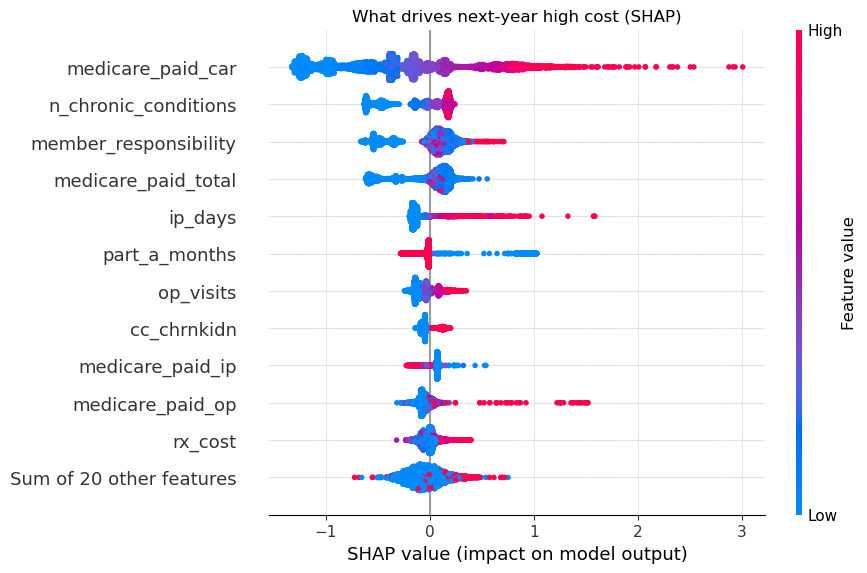

In [12]:
import shap
sample = Xte.sample(5000, random_state=0)
sv = shap.TreeExplainer(booster)(sample)            # log-odds contributions
shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("What drives next-year high cost (SHAP)"); plt.show()

In [13]:
# Track the model, its parameters, and metrics in MLflow, and register it.
import logging, mlflow
logging.getLogger("mlflow").setLevel(logging.WARNING)
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
mlflow.set_experiment("high_cost_risk")
with mlflow.start_run(run_name="xgboost_oot_2008_2009"):
    mlflow.log_params({**XGB_PARAMS, "train_year": 2008, "test_year": 2009})
    mlflow.log_metrics(risk_results.loc["xgboost"].to_dict())
    mlflow.xgboost.log_model(booster, name="model", input_example=Xte.head(3), registered_model_name="high_cost_risk")

Successfully registered model 'high_cost_risk'.
Created version '1' of model 'high_cost_risk'.


### Results

| Model | ROC AUC | PR AUC | Top-5% capture |
|---|---|---|---|
| Baseline: prior-year cost | 0.708 | 0.104 | 14.4% |
| **XGBoost** | **0.744** | **0.178** | **21.0%** |

- For the same outreach budget, XGBoost reaches about **46% more** of next year's high-cost members than calling last year's most expensive members.
- SHAP shows physician/carrier spend and chronic-condition count driving the predictions. Ongoing care and comorbidity burden persist from year to year more reliably than a single hospital stay.